# PH1050 Final Project — Part 2(a): Kepler's Third Law fit for the 8 planets

**Task:** Fit $\log T$ against $\log a$ for the 8 planets, give the slope with a 95% confidence interval, and check whether 1.5 lies inside it.

**Physics:** In units of AU, years and solar masses ($GM = 4\pi^2$), Kepler's third law is
$$T^2 = a^3 \quad\Rightarrow\quad \log T = 1.5\,\log a + 0$$
So on a log–log plot the points should lie on a straight line of **slope 1.5** and **intercept 0**.

**Method:** least-squares straight-line fit $y = m x + c$ with $x = \log_{10} a$, $y = \log_{10} T$, then a 95% confidence interval using the t-distribution with $n-2 = 6$ degrees of freedom.

**Data:** semi-major axes and observed periods are from the NASA Planetary Fact Sheet; simulated periods come from the RK4 simulation in Part 1 (8-planet simulation).

In [2]:
# Step 0: Import libraries

import numpy as np                 # arrays and maths
import matplotlib.pyplot as plt    # plotting
from scipy import stats            # only used to get the t-value

## Step 1: Data for the 8 planets

In [3]:
# Step 1: Data  (same values as Part 1)

names = ["Mercury", "Venus", "Earth", "Mars", "Jupiter", "Saturn", "Uranus", "Neptune"]

# Semi-major axis a in AU (NASA Planetary Fact Sheet)
a = np.array([0.387098, 0.723332, 1.000000, 1.523679, 5.204400, 9.582600, 19.21840, 30.11000])

# Observed orbital period T in years (NASA Planetary Fact Sheet)
T_obs = np.array([0.240846, 0.615198, 1.000017, 1.880849, 11.86200, 29.45710, 84.01200, 164.7885])

# Simulated orbital period T in years (RK4 simulation from Part 1)
T_sim = np.array([0.240842, 0.615186, 1.000000, 1.880790, 11.872878, 29.663681, 84.251151, 165.221337])

print("Number of planets n =", len(a))

Number of planets n = 8


## Step 2: The fitting function
## New section
For $n$ points $(x_i, y_i)$, the least-squares line $y = m x + c$ has

$$m = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2}, \qquad c = \bar y - m\bar x$$

Residual standard deviation and standard error of the slope:

$$s = \sqrt{\frac{\sum (y_i - m x_i - c)^2}{n-2}}, \qquad SE(m) = \frac{s}{\sqrt{\sum (x_i-\bar x)^2}}$$

95% confidence interval: $\; m \pm t_{0.975,\,n-2}\cdot SE(m)$, with $t_{0.975,6} \approx 2.447$.

In [6]:
# Step 2: Function that fits log T vs log a and gives a 95% CI

def kepler_fit(a, T):
    x = np.log10(a)
    y = np.log10(T)
    n = len(x)

    # Means of x and y
    x_mean = np.mean(x)
    y_mean = np.mean(y)

    # Least-squares slope and intercept
    # Where Sxx = ∑(𝑥𝑖−𝑥¯)(𝑦𝑖−𝑦¯) and Sxy = ∑(𝑥𝑖−𝑥¯)2
    Sxx = np.sum((x - x_mean)**2)
    Sxy = np.sum((x - x_mean) * (y - y_mean))
    m = Sxy / Sxx
    c = y_mean - m * x_mean

     # Residuals = data minus fitted line
    residuals = y - (m * x + c)

    # Standard error of the slope (n - 2 degrees of freedom)
    s = np.sqrt(np.sum(residuals**2) / (n - 2))
    SE_m = s / np.sqrt(Sxx)

    # t-value for a 95% two-sided interval with n - 2 = 6 degrees of freedom
    t_val = stats.t.ppf(0.975, n - 2)

    # 95% confidence interval for the slope
    m_low  = m - t_val * SE_m
    m_high = m + t_val * SE_m

    return m, c, SE_m, t_val, m_low, m_high, residuals

## Step 3: Fit the observed (NASA) periods: main result

In [7]:
# Step 3: Fit using the OBSERVED periods

m, c, SE_m, t_val, m_low, m_high, res_obs = kepler_fit(a, T_obs)

print("Fit: log10 T = m * log10 a + c   (observed periods)")
print(f"Slope m           = {m:.5f}")
print(f"Intercept c       = {c:.5f}")
print(f"Std error SE(m)   = {SE_m:.5f}")
print(f"t-value (6 dof)   = {t_val:.3f}")
print(f"95% CI for slope  = [{m_low:.5f}, {m_high:.5f}]")

# Is Kepler's value 1.5 inside the interval?
if m_low <= 1.5 <= m_high:
    print("\n1.5 IS inside the 95% confidence interval -> consistent with Kepler's third law")
else:
    print("\n1.5 is NOT inside the 95% confidence interval")

# How many standard errors is the slope away from 1.5?
print(f"Distance of slope from 1.5 = {(m - 1.5)/SE_m:.2f} standard errors (limit is +/- {t_val:.3f})")

Fit: log10 T = m * log10 a + c   (observed periods)
Slope m           = 1.49896
Intercept c       = -0.00019
Std error SE(m)   = 0.00046
t-value (6 dof)   = 2.447
95% CI for slope  = [1.49784, 1.50007]

1.5 IS inside the 95% confidence interval -> consistent with Kepler's third law
Distance of slope from 1.5 = -2.28 standard errors (limit is +/- 2.447)


## Step 4: Same fit using the simulated periods (cross check)

In [8]:
# Step 4: Fit using the SIMULATED periods from Part 1
m_s, c_s, SE_s, t_s, low_s, high_s, res_sim = kepler_fit(a, T_sim)

print("Fit: log10 T = m * log10 a + c   (simulated periods)")
print(f"Slope m           = {m_s:.7f}")
print(f"Intercept c       = {c_s:.7f}")
print(f"Std error SE(m)   = {SE_s:.2e}")
print(f"95% CI for slope  = [{low_s:.7f}, {high_s:.7f}]")
print("1.5 inside CI?   ", low_s <= 1.5 <= high_s)

Fit: log10 T = m * log10 a + c   (simulated periods)
Slope m           = 1.4999998
Intercept c       = 0.0000002
Std error SE(m)   = 1.48e-07
95% CI for slope  = [1.4999994, 1.5000001]
1.5 inside CI?    True


## Step 5: Plots

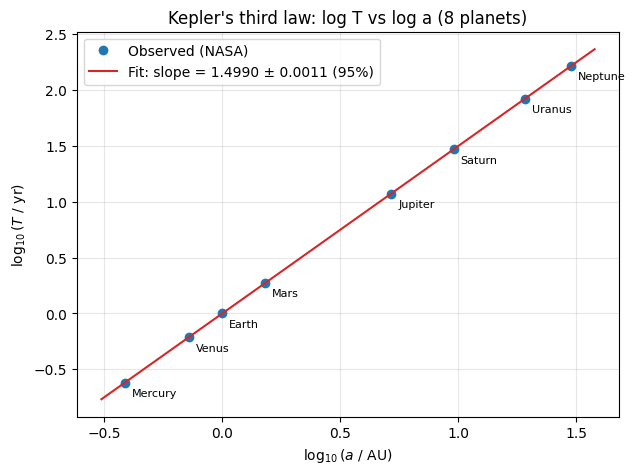

In [9]:
# Step 5: log-log plot of the data with the fitted line

x_obs = np.log10(a)
y_obs = np.log10(T_obs)
x_line = np.linspace(min(x_obs) - 0.1, max(x_obs) + 0.1, 100)

plt.figure(figsize=(7, 5))
plt.plot(x_obs, y_obs, 'o', color='tab:blue', label='Observed (NASA)')
plt.plot(x_line, m * x_line + c, '-', color='tab:red',
         label=f'Fit: slope = {m:.4f} ± {t_val*SE_m:.4f} (95%)')
for i in range(len(names)):
    plt.annotate(names[i], (x_obs[i], y_obs[i]), textcoords='offset points', xytext=(5, -10), fontsize=8)
plt.xlabel(r'$\log_{10}(a\ /\ \mathrm{AU})$')
plt.ylabel(r'$\log_{10}(T\ /\ \mathrm{yr})$')
plt.title("Kepler's third law: log T vs log a (8 planets)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

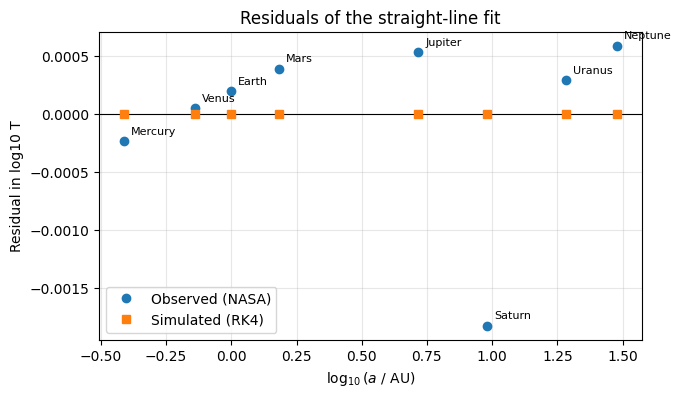

In [10]:
# Step 6: residual plot (data minus fitted line)

plt.figure(figsize=(7, 4))
plt.axhline(0, color='black', linewidth=0.8)
plt.plot(x_obs, res_obs, 'o', color='tab:blue', label='Observed (NASA)')
plt.plot(x_obs, res_sim, 's', color='tab:orange', label='Simulated (RK4)')
for i in range(len(names)):
    plt.annotate(names[i], (x_obs[i], res_obs[i]), textcoords='offset points', xytext=(5, 5), fontsize=8)
plt.xlabel(r'$\log_{10}(a\ /\ \mathrm{AU})$')
plt.ylabel('Residual in log10 T')
plt.title('Residuals of the straight-line fit')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Step 6: Summary table

In [11]:
# Step 6: Summary

print(f"{'Data':<12} {'Slope':<12} {'95% CI':<28} {'1.5 inside?'}")
print("-" * 64)
print(f"{'Observed':<12} {m:<12.5f} [{m_low:.5f}, {m_high:.5f}]{'':<5} {m_low <= 1.5 <= m_high}")
print(f"{'Simulated':<12} {m_s:<12.7f} [{low_s:.7f}, {high_s:.7f}]  {low_s <= 1.5 <= high_s}")

Data         Slope        95% CI                       1.5 inside?
----------------------------------------------------------------
Observed     1.49896      [1.49784, 1.50007]      True
Simulated    1.4999998    [1.4999994, 1.5000001]  True
